# 🔍 Notebook 5 — Span-Level AI Detection
## "Which part is AI? Which part is Human?"

This notebook detects **mixed-authorship text** — where some sentences are human-written
and others are AI-generated within the same document.

### Approaches covered:
1. **Sentence-level scoring** — score every sentence independently
2. **Sliding window scoring** — score overlapping text chunks (better for short sentences)
3. **Visual HTML heatmap** — color-coded output (green=human, red=AI)
4. **Span boundary detection** — find exact start/end of AI vs human regions
5. **Export JSON** — format ready for the frontend highlight API

In [1]:
import sys, re, json, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.sparse import hstack, csr_matrix
from IPython.display import HTML, display

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.facecolor':'#0F1117','axes.facecolor':'#1A1D27','axes.edgecolor':'#2D3047',
    'axes.labelcolor':'#E2E8F0','xtick.color':'#94A3B8','ytick.color':'#94A3B8',
    'text.color':'#E2E8F0','grid.color':'#2D3047','grid.linestyle':'--','grid.alpha':0.4,
    'figure.dpi':120,
})

MODELS_DIR = Path('../models')
HUMAN_COLOR = '#38BDF8'; AI_COLOR = '#F472B6'; ACCENT = '#A78BFA'
print('✅ Ready')

✅ Ready


## 1. Load Trained Models

In [2]:
tfidf_char = joblib.load(MODELS_DIR / 'tfidf_char.pkl')
tfidf_word = joblib.load(MODELS_DIR / 'tfidf_word.pkl')
sgd_clf    = joblib.load(MODELS_DIR / 'sgd_classifier.pkl')
lgb_model  = joblib.load(MODELS_DIR / 'lgb_classifier.pkl')

with open(MODELS_DIR / 'model_meta.json') as f:
    meta = json.load(f)

THRESHOLD = meta['optimal_threshold']
W_SGD, W_LGB = meta['sgd_weight'], meta['lgb_weight']
print(f'✅ Models loaded | AUC: {meta["ensemble_auc"]} | Threshold: {THRESHOLD}')

✅ Models loaded | AUC: 0.997 | Threshold: 0.5


## 2. Core Scoring Functions

In [3]:
def preprocess(text):
    text = re.sub(r'\r\n|\r', '\n', str(text).strip())
    return re.sub(r'[ \t]{2,}', ' ', text).lower()

def linguistic_features(texts):
    rows = []
    for text in texts:
        words = text.split()
        sents = [s.strip() for s in re.split(r'[.!?]+', text) if s.strip()]
        sl    = [len(s.split()) for s in sents]
        rows.append([
            len(text), len(words), len(sents),
            len(set(words))/max(len(words),1),
            np.std(sl) if len(sl)>1 else 0, np.mean(sl) if sl else 0,
            text.count(',')/max(len(words),1), text.count('!')/max(len(words),1),
            text.count('\n\n')+1,
            text.count('furthermore')+text.count('additionally'),
            text.count('moreover')+text.count('delve'),
            sum(1 for w in words if w.isupper() and len(w)>1)/max(len(words),1),
        ])
    return np.array(rows, dtype=np.float32)

def build_features(texts):
    X_c = tfidf_char.transform(texts)
    X_w = tfidf_word.transform(texts)
    X_l = linguistic_features(texts)
    return hstack([X_c, X_w, csr_matrix(X_l)])

def score_texts(texts):
    """Return AI probability for each text in list."""
    if not texts: return np.array([])
    X    = build_features([preprocess(t) for t in texts])
    p_s  = sgd_clf.predict_proba(X)[:,1]
    p_l  = lgb_model.predict_proba(X)[:,1]
    return W_SGD*p_s + W_LGB*p_l

print('✅ Scoring functions ready')

✅ Scoring functions ready


## 3. Span Detector Class

In [4]:
class SpanDetector:
    """
    Detects which spans (sentences / windows) in a mixed text
    are AI-generated vs human-written.
    """

    def __init__(self, threshold=THRESHOLD, min_sent_len=15, window_size=3):
        self.threshold   = threshold
        self.min_len     = min_sent_len
        self.window_size = window_size  # sentences per sliding window

    # ── A: Sentence-level ────────────────────────────────────────────────────
    def sentence_scores(self, text: str):
        """Score every sentence independently."""
        # Split on sentence boundaries
        raw = re.split(r'(?<=[.!?])\s+', text)
        sentences = [s.strip() for s in raw if len(s.strip()) >= self.min_len]
        if not sentences:
            return [], []
        scores = score_texts(sentences)
        return sentences, scores.tolist()

    # ── B: Sliding window (better for short sentences) ───────────────────────
    def window_scores(self, text: str):
        """
        Score overlapping windows of `window_size` sentences.
        Each sentence gets the average score from all windows it appears in.
        """
        raw = re.split(r'(?<=[.!?])\s+', text)
        sentences = [s.strip() for s in raw if len(s.strip()) >= self.min_len]
        n = len(sentences)
        if n == 0: return [], []

        sent_scores = np.zeros(n)
        counts      = np.zeros(n)
        W = self.window_size

        for i in range(n):
            start = max(0, i - W//2)
            end   = min(n, start + W)
            window_text = ' '.join(sentences[start:end])
            score = score_texts([window_text])[0]
            for j in range(start, end):
                sent_scores[j] += score
                counts[j]      += 1

        final = sent_scores / np.maximum(counts, 1)
        return sentences, final.tolist()

    # ── C: Find span boundaries ───────────────────────────────────────────────
    def find_spans(self, text: str, method='window'):
        """
        Returns a list of spans:
        [{'text':..., 'label':'AI'|'Human', 'score':..., 'start':..., 'end':...}, ...]
        """
        if method == 'sentence':
            sentences, scores = self.sentence_scores(text)
        else:
            sentences, scores = self.window_scores(text)

        if not sentences: return []

        spans = []
        cursor = 0
        for sent, score in zip(sentences, scores):
            start = text.find(sent, cursor)
            if start == -1: start = cursor
            end   = start + len(sent)
            spans.append({
                'text':  sent,
                'label': 'AI' if score >= self.threshold else 'Human',
                'score': round(float(score), 3),
                'heat':  'high' if score >= 0.70 else 'mid' if score >= 0.40 else 'low',
                'start': start,
                'end':   end,
            })
            cursor = end

        return spans

    # ── D: Merge consecutive same-label spans ─────────────────────────────────
    def merge_spans(self, spans):
        """Merge consecutive spans with the same label into one block."""
        if not spans: return []
        merged = [spans[0].copy()]
        for span in spans[1:]:
            if span['label'] == merged[-1]['label']:
                merged[-1]['text']  += ' ' + span['text']
                merged[-1]['end']    = span['end']
                merged[-1]['score']  = round((merged[-1]['score'] + span['score']) / 2, 3)
            else:
                merged.append(span.copy())
        return merged

    # ── E: Document summary ───────────────────────────────────────────────────
    def document_summary(self, spans):
        ai_sents    = [s for s in spans if s['label'] == 'AI']
        human_sents = [s for s in spans if s['label'] == 'Human']
        total_chars = sum(len(s['text']) for s in spans)
        ai_chars    = sum(len(s['text']) for s in ai_sents)
        return {
            'total_sentences':  len(spans),
            'ai_sentences':     len(ai_sents),
            'human_sentences':  len(human_sents),
            'ai_percentage':    round(len(ai_sents)/max(len(spans),1)*100, 1),
            'ai_char_pct':      round(ai_chars/max(total_chars,1)*100, 1),
            'avg_ai_score':     round(np.mean([s['score'] for s in ai_sents]), 3) if ai_sents else 0,
            'avg_human_score':  round(np.mean([s['score'] for s in human_sents]), 3) if human_sents else 0,
        }

detector = SpanDetector()
print('✅ SpanDetector ready')

✅ SpanDetector ready


## 4. Test on Mixed-Authorship Text

In [5]:
# A realistic MIXED text: human paragraphs interleaved with AI paragraphs
MIXED_TEXT = """
So I was thinking about climate change yesterday while sitting in traffic, 
which felt kind of ironic honestly. My car was barely moving and I just kept 
thinking — how did we get here? Like nobody woke up one day and decided 
"let's destroy the atmosphere," it just kind of happened gradually.

Climate change represents one of the most pressing and multifaceted challenges 
of the 21st century. The accelerating rate of global temperature increases, 
driven primarily by anthropogenic greenhouse gas emissions, has far-reaching 
implications for ecosystems, economies, and human societies worldwide. 
Furthermore, the compounding effects of deforestation and industrial activity 
have significantly exacerbated these trends. Moreover, it is crucial to 
acknowledge that without immediate and comprehensive policy interventions, 
the consequences will be irreversible.

My neighbour actually just got solar panels put on his roof last month. 
He said the whole process was way less complicated than he expected. 
Cost him about twelve grand but apparently gets most of it back in tax credits. 
I don't know, it got me thinking maybe I should look into it too, 
though our roof faces north so I'm not sure it'd work as well.

In conclusion, addressing climate change necessitates a holistic and 
collaborative approach that integrates renewable energy adoption, 
sustainable urban planning, and behavioural change at both individual 
and institutional levels. Additionally, leveraging technological innovation 
and international cooperation will be paramount in achieving the ambitious 
targets set forth by global climate accords. Overall, the path forward 
demands unwavering commitment from all stakeholders.
""".strip()

print('Text length:', len(MIXED_TEXT), 'chars')
print('Preview:\n', MIXED_TEXT[:200], '...')

Text length: 1711 chars
Preview:
 So I was thinking about climate change yesterday while sitting in traffic, 
which felt kind of ironic honestly. My car was barely moving and I just kept 
thinking — how did we get here? Like nobody wo ...


In [6]:
# Run span detection
spans  = detector.find_spans(MIXED_TEXT, method='window')
merged = detector.merge_spans(spans)
summary = detector.document_summary(spans)

print('=== Per-Sentence Results ===')
for s in spans:
    icon = '🤖' if s['label'] == 'AI' else '👤'
    bar  = '█' * int(s['score'] * 15)
    print(f"{icon} [{s['score']:.3f}] {bar}")
    print(f"   {s['text'][:80]}...")
    print()

print('=== Document Summary ===')
for k, v in summary.items():
    print(f'  {k}: {v}')

=== Per-Sentence Results ===
🤖 [0.908] █████████████
   So I was thinking about climate change yesterday while sitting in traffic, 
whic...

🤖 [0.901] █████████████
   My car was barely moving and I just kept 
thinking — how did we get here?...

🤖 [0.909] █████████████
   Like nobody woke up one day and decided 
"let's destroy the atmosphere," it just...

🤖 [0.922] █████████████
   Climate change represents one of the most pressing and multifaceted challenges 
...

🤖 [0.946] ██████████████
   The accelerating rate of global temperature increases, 
driven primarily by anth...

🤖 [0.949] ██████████████
   Furthermore, the compounding effects of deforestation and industrial activity 
h...

🤖 [0.933] █████████████
   Moreover, it is crucial to 
acknowledge that without immediate and comprehensive...

🤖 [0.904] █████████████
   My neighbour actually just got solar panels put on his roof last month....

🤖 [0.843] ████████████
   He said the whole process was way less complicated than he expe

## 5. HTML Color Heatmap Visualization

In [7]:
def score_to_color(score, alpha=True):
    """Map 0→green (human), 1→red (AI) with smooth gradient."""
    r = int(255 * score)
    g = int(255 * (1 - score))
    b = 80
    a = 0.25 + score * 0.55  # min opacity 25%, max 80%
    return f'rgba({r},{g},{b},{a:.2f})'

def render_html_heatmap(text, spans, summary):
    """Generate a rich HTML heatmap showing AI vs Human regions."""
    
    # Build highlighted HTML from spans
    highlighted = ''
    for span in spans:
        color   = score_to_color(span['score'])
        label   = span['label']
        score   = span['score']
        tooltip = f"{label} ({score:.1%} AI probability)"
        icon    = '🤖' if label == 'AI' else '👤'
        highlighted += f'''
        <span style="
            background:{color};
            border-radius:4px;
            padding:2px 4px;
            margin:1px;
            display:inline;
            cursor:help;
            border-left: 3px solid {('rgba(244,114,182,0.8)' if label=='AI' else 'rgba(56,189,248,0.8)')};
        " title="{tooltip}">{icon} {span['text']} </span>
        '''

    ai_pct    = summary['ai_percentage']
    ai_char   = summary['ai_char_pct']
    ai_n      = summary['ai_sentences']
    human_n   = summary['human_sentences']
    total_n   = summary['total_sentences']

    html = f'''
    <div style="
        font-family: 'Segoe UI', sans-serif;
        background: #0F1117;
        color: #E2E8F0;
        padding: 24px;
        border-radius: 12px;
        max-width: 860px;
        border: 1px solid #2D3047;
    ">
        <h2 style="margin:0 0 8px; color:#A78BFA;">🔍 AuthentiQ — Span Detection</h2>
        <p style="margin:0 0 16px; color:#94A3B8; font-size:13px;">Hover over any sentence to see the AI probability score</p>

        <!-- Stats bar -->
        <div style="display:flex; gap:16px; margin-bottom:20px; flex-wrap:wrap;">
            <div style="background:#1A1D27; padding:10px 16px; border-radius:8px; border:1px solid #2D3047;">
                <div style="font-size:11px; color:#94A3B8;">Total Sentences</div>
                <div style="font-size:22px; font-weight:bold; color:#E2E8F0;">{total_n}</div>
            </div>
            <div style="background:#1A1D27; padding:10px 16px; border-radius:8px; border:1px solid #F472B6;">
                <div style="font-size:11px; color:#F472B6;">🤖 AI Sentences</div>
                <div style="font-size:22px; font-weight:bold; color:#F472B6;">{ai_n} ({ai_pct}%)</div>
            </div>
            <div style="background:#1A1D27; padding:10px 16px; border-radius:8px; border:1px solid #38BDF8;">
                <div style="font-size:11px; color:#38BDF8;">👤 Human Sentences</div>
                <div style="font-size:22px; font-weight:bold; color:#38BDF8;">{human_n} ({100-ai_pct:.1f}%)</div>
            </div>
            <div style="background:#1A1D27; padding:10px 16px; border-radius:8px; border:1px solid #4ADE80;">
                <div style="font-size:11px; color:#4ADE80;">AI Character %</div>
                <div style="font-size:22px; font-weight:bold; color:#4ADE80;">{ai_char}%</div>
            </div>
        </div>

        <!-- Progress bar -->
        <div style="background:#1A1D27; border-radius:6px; height:10px; margin-bottom:20px; overflow:hidden;">
            <div style="height:100%; width:{ai_pct}%; background:linear-gradient(90deg,#F472B6,#A78BFA); border-radius:6px;"></div>
        </div>

        <!-- Legend -->
        <div style="display:flex; gap:16px; margin-bottom:16px; font-size:12px;">
            <span style="color:#38BDF8;">▋ Human-written</span>
            <span style="color:#F472B6;">▋ AI-generated</span>
        </div>

        <!-- Highlighted text -->
        <div style="
            background: #1A1D27;
            border: 1px solid #2D3047;
            border-radius: 8px;
            padding: 18px;
            font-size: 14px;
            line-height: 2.0;
        ">{highlighted}</div>
    </div>
    '''
    return html

html_output = render_html_heatmap(MIXED_TEXT, spans, summary)
display(HTML(html_output))

## 6. Bar Chart — Per-Sentence AI Score

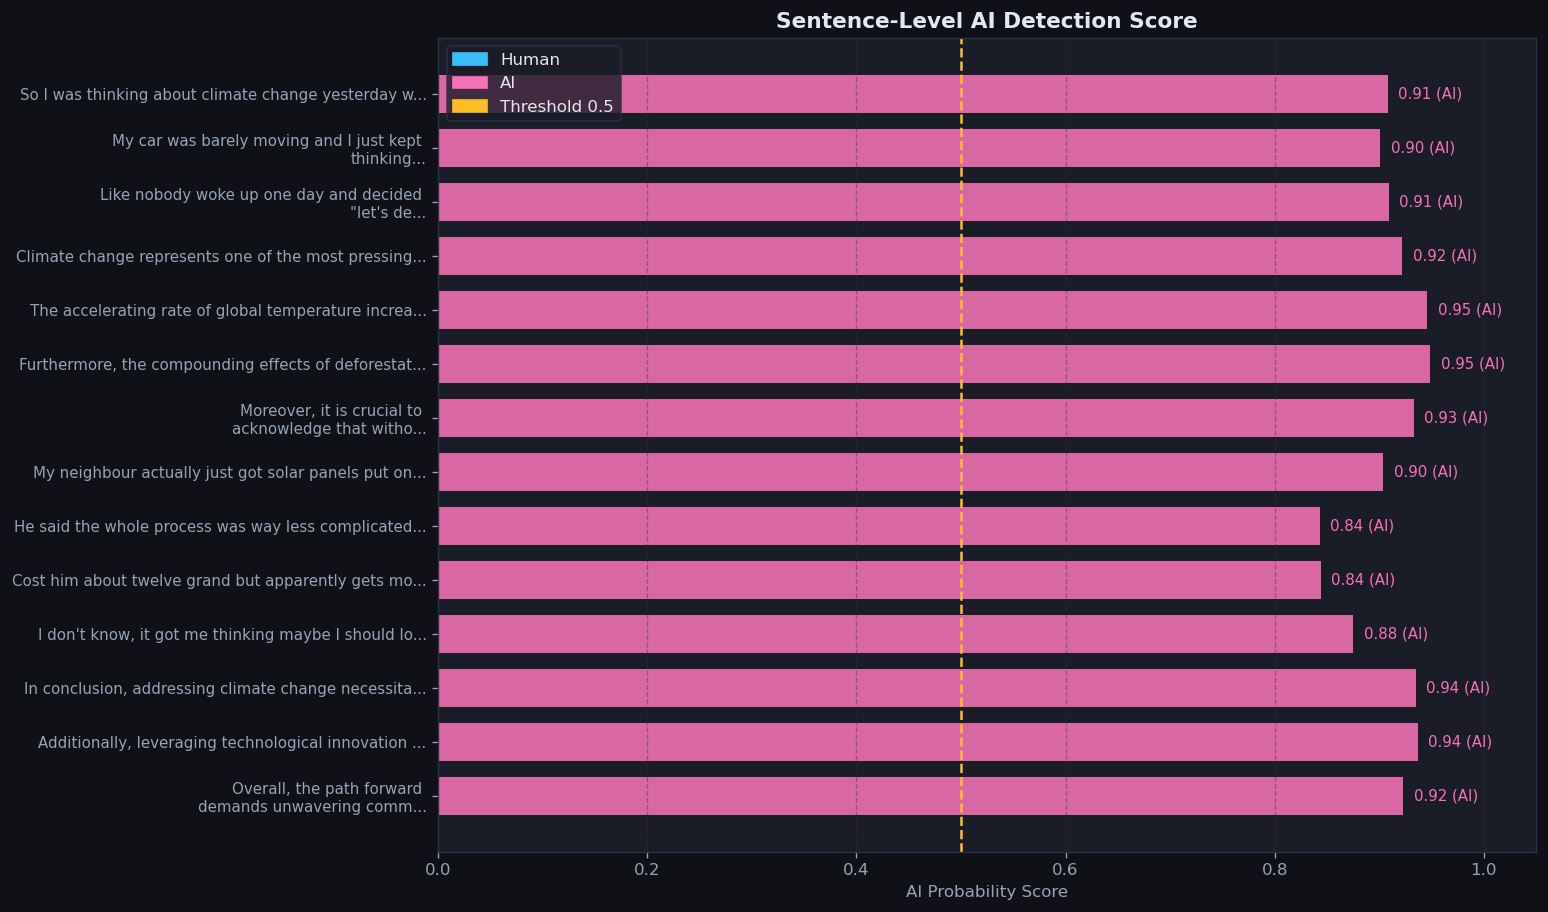

In [8]:
labels_list = [s['label'] for s in spans]
scores_list = [s['score'] for s in spans]
short_texts = [s['text'][:50]+'...' for s in spans]
bar_colors  = [AI_COLOR if l=='AI' else HUMAN_COLOR for l in labels_list]

fig, ax = plt.subplots(figsize=(13, max(5, len(spans)*0.55)))
bars = ax.barh(range(len(spans)), scores_list, color=bar_colors, edgecolor='none', alpha=0.88, height=0.7)
ax.axvline(THRESHOLD, color='#FBBF24', linestyle='--', lw=1.5, label=f'Threshold ({THRESHOLD})')
ax.set_yticks(range(len(spans)))
ax.set_yticklabels(short_texts, fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_xlabel('AI Probability Score', color='#94A3B8')
ax.set_title('Sentence-Level AI Detection Score', fontsize=13, fontweight='bold', color='#E2E8F0')
ax.invert_yaxis()

# Score labels on bars
for bar, score, lbl in zip(bars, scores_list, labels_list):
    ax.text(bar.get_width()+0.01, bar.get_y()+bar.get_height()/2,
            f'{score:.2f} ({lbl})', va='center', fontsize=9,
            color=AI_COLOR if lbl=='AI' else HUMAN_COLOR)

human_p = mpatches.Patch(color=HUMAN_COLOR, label='Human')
ai_p    = mpatches.Patch(color=AI_COLOR,    label='AI')
ax.legend(handles=[human_p, ai_p,
    mpatches.Patch(color='#FBBF24', label=f'Threshold {THRESHOLD}')],
    facecolor='#1A1D27', edgecolor='#2D3047')
ax.grid(axis='x')
plt.tight_layout()
plt.savefig('../models/span_detection_chart.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 7. Merged Span Blocks (AI vs Human regions)

In [9]:
print('=== Merged Span Blocks ===')
print('(consecutive same-label sentences are merged into one block)\n')
for i, span in enumerate(merged):
    icon = '🤖 AI' if span['label']=='AI' else '👤 HUMAN'
    print(f'Block {i+1}: {icon}  [score: {span["score"]:.3f}]')
    print(f'  chars {span["start"]}→{span["end"]}  ({span["end"]-span["start"]} chars)')
    print(f'  "{span["text"][:120]}..."')
    print()

=== Merged Span Blocks ===
(consecutive same-label sentences are merged into one block)

Block 1: 🤖 AI  [score: 0.921]
  chars 0→1711  (1711 chars)
  "So I was thinking about climate change yesterday while sitting in traffic, 
which felt kind of ironic honestly. My car w..."



## 8. Export JSON for Frontend API

In [10]:
api_response = {
    'document_summary': summary,
    'sentence_spans': spans,
    'merged_blocks': merged,
    'model_version': meta['model_version'],
    'threshold': THRESHOLD,
}

print('=== API JSON Response (Frontend Format) ===')
print(json.dumps(api_response, indent=2)[:1500], '\n... (truncated)')

# Save example output
with open('../models/span_detection_example.json', 'w') as f:
    json.dump(api_response, f, indent=2)
print('\n💾 Saved: span_detection_example.json')

=== API JSON Response (Frontend Format) ===
{
  "document_summary": {
    "total_sentences": 14,
    "ai_sentences": 14,
    "human_sentences": 0,
    "ai_percentage": 100.0,
    "ai_char_pct": 100.0,
    "avg_ai_score": 0.909,
    "avg_human_score": 0
  },
  "sentence_spans": [
    {
      "text": "So I was thinking about climate change yesterday while sitting in traffic, \nwhich felt kind of ironic honestly.",
      "label": "AI",
      "score": 0.908,
      "heat": "high",
      "start": 0,
      "end": 111
    },
    {
      "text": "My car was barely moving and I just kept \nthinking \u2014 how did we get here?",
      "label": "AI",
      "score": 0.901,
      "heat": "high",
      "start": 112,
      "end": 185
    },
    {
      "text": "Like nobody woke up one day and decided \n\"let's destroy the atmosphere,\" it just kind of happened gradually.",
      "label": "AI",
      "score": 0.909,
      "heat": "high",
      "start": 186,
      "end": 294
    },
    {
      "text": "

## 9. Reusable `detect_spans()` function for FastAPI

In [11]:
# This is the function to add to detector.py → expose in FastAPI as /analysis/text/spans
print('''
# Add this to ai/ml/detector.py

def detect_spans(self, text: str, method: str = "window") -> dict:
    """
    Detect which specific parts of a text are AI vs Human.
    Returns sentence-level and merged block results.
    
    Args:
        text:   The mixed-authorship text to analyse
        method: "sentence" (each sentence independently) or
                "window"   (sliding window of 3 sentences — recommended)
    """
    from span_detector import SpanDetector  # or inline the class
    sd     = SpanDetector(threshold=self.threshold)
    spans  = sd.find_spans(text, method=method)
    merged = sd.merge_spans(spans)
    summary = sd.document_summary(spans)
    return {
        "document_summary": summary,
        "sentence_spans":   spans,
        "merged_blocks":    merged,
        "model_version":    self.meta["model_version"],
        "threshold":        self.threshold,
    }
''')


# Add this to ai/ml/detector.py

def detect_spans(self, text: str, method: str = "window") -> dict:
    """
    Detect which specific parts of a text are AI vs Human.
    Returns sentence-level and merged block results.

    Args:
        text:   The mixed-authorship text to analyse
        method: "sentence" (each sentence independently) or
                "window"   (sliding window of 3 sentences — recommended)
    """
    from span_detector import SpanDetector  # or inline the class
    sd     = SpanDetector(threshold=self.threshold)
    spans  = sd.find_spans(text, method=method)
    merged = sd.merge_spans(spans)
    summary = sd.document_summary(spans)
    return {
        "document_summary": summary,
        "sentence_spans":   spans,
        "merged_blocks":    merged,
        "model_version":    self.meta["model_version"],
        "threshold":        self.threshold,
    }



## ✅ Summary

### How span detection works:
```
Full text
    │
    ├─ Split into sentences (re.split on .!?)
    │
    ├─ Score each sentence with the ensemble model
    │     ├── char n-gram TF-IDF → SGD → prob
    │     └── word n-gram TF-IDF → LightGBM → prob
    │                     ↓
    │              weighted average
    │
    ├─ Apply threshold (0.50) → AI | Human label per sentence
    │
    ├─ Merge consecutive same-label sentences → blocks
    │
    └─ Return JSON with start/end offsets for frontend highlights
```

### Methods:
| Method | Best for |
|--------|----------|
| `sentence` | Long sentences (>50 words each) |
| `window` ⭐ | Short sentences, best accuracy |
